   Зарегистрировано фотоэлектронов: 111


Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [E, x, y, z]
Sampling 4 chains for 500 tune and 1_000 draw iterations (2_000 + 4_000 draws total) took 3 seconds.


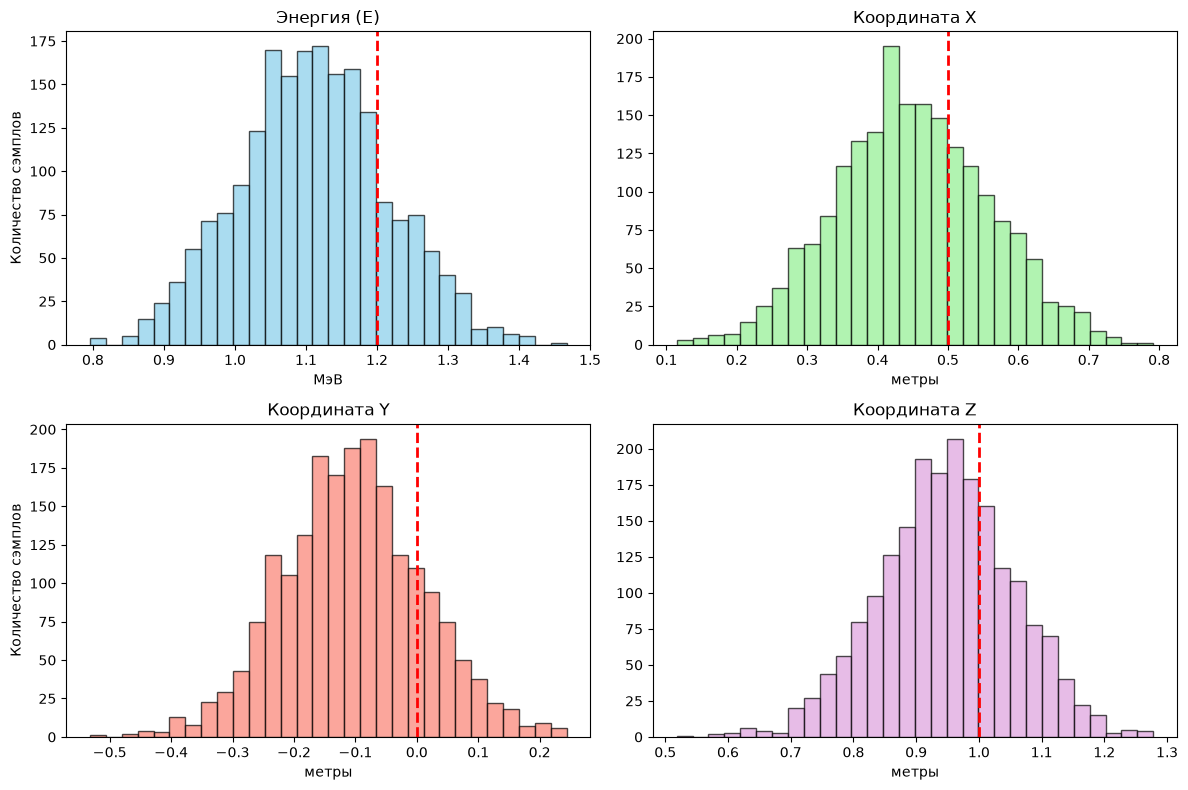

Энергия (E): 1.111 ± 0.105 МэВ  (Истина: 1.2)
Координата X: 0.449 ± 0.109 м    (Истина: 0.5)
Координата Y: -0.105 ± 0.115 м    (Истина: 0.0)
Координата Z: 0.947 ± 0.108 м    (Истина: 1.0)


In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pytensor
import pytensor.tensor as pt
import pymc as pm
import arviz as az
pytensor.config.cxx = "" 


R = 2.0       # Радиус детектора, м
N_pmts = 40   # Количество ФЭУ
r = 0.1       # Радиус ФЭУ, м
a = 0.5       # Квантовая эффективность
Y = 10000     # Выход фотонов на МэВ
L = 8.0       # Длина затухания, м


indices = np.arange(0, N_pmts, dtype=float) + 0.5
phi = np.arccos(1 - 2 * indices / N_pmts)
theta = np.pi * (1 + 5**0.5) * indices

x_pmt = np.cos(theta) * np.sin(phi) * R
y_pmt = np.sin(theta) * np.sin(phi) * R
z_pmt = np.cos(phi) * R

pmt_positions = np.column_stack([x_pmt, y_pmt, z_pmt])
pmt_normals = pmt_positions / R



E_true = 1.2
x_true, y_true, z_true = 0.5, 0.0, 1.0

source_pos_true = np.array([x_true, y_true, z_true])
vec_to_pmt = pmt_positions - source_pos_true
distances = np.linalg.norm(vec_to_pmt, axis=1)


cos_theta = np.abs(np.sum(pmt_normals * vec_to_pmt, axis=1)) / distances
area = np.pi * r**2
solid_angle = (area * cos_theta) / (distances**2)
fraction = solid_angle / (4 * np.pi)
survival_prob = np.exp(-distances / L)


expected_pe_true = a * Y * E_true * fraction * survival_prob
np.random.seed(5) 
observed_pe = np.random.poisson(expected_pe_true)
print(f"   Зарегистрировано фотоэлектронов: {observed_pe.sum()}")



with pm.Model() as recon_model:
    E = pm.Uniform('E', lower=0, upper=5)
    x = pm.Uniform('x', lower=-1.9, upper=1.9)
    y = pm.Uniform('y', lower=-1.9, upper=1.9)
    z = pm.Uniform('z', lower=-1.9, upper=1.9)
    

    source_pos = pt.stack([x, y, z])
    vec = pt.as_tensor_variable(pmt_positions) - source_pos
    dist = pt.sqrt(pt.sum(vec**2, axis=1))
    
    cos_t = pt.abs(pt.sum(pmt_normals * vec, axis=1)) / dist
    solid_ang = (area * cos_t) / (dist**2)
    mu_pe = a * Y * E * (solid_ang / (4 * np.pi)) * pt.exp(-dist / L)

    obs = pm.Poisson('obs', mu=mu_pe, observed=observed_pe)




with recon_model:
    trace = pm.sample(
        draws=1000, 
        tune=500, 
        chains=4,        
        cores=1,         
        target_accept=0.8,
        progressbar=False 
    )



fig, axes = plt.subplots(2, 2, figsize=(12, 8))


# --- График E ---
axes[0, 0].hist(samples_E, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
axes[0, 0].axvline(E_true, color='red', linestyle='dashed', linewidth=2)
axes[0, 0].set_title('Энергия (E)')
axes[0, 0].set_xlabel('МэВ')
axes[0, 0].set_ylabel('Количество сэмплов')

# --- График x ---
axes[0, 1].hist(samples_x, bins=30, alpha=0.7, color='lightgreen', edgecolor='black')
axes[0, 1].axvline(x_true, color='red', linestyle='dashed', linewidth=2)
axes[0, 1].set_title('Координата X')
axes[0, 1].set_xlabel('метры')

# --- График y ---
axes[1, 0].hist(samples_y, bins=30, alpha=0.7, color='salmon', edgecolor='black')
axes[1, 0].axvline(y_true, color='red', linestyle='dashed', linewidth=2)
axes[1, 0].set_title('Координата Y')
axes[1, 0].set_xlabel('метры')
axes[1, 0].set_ylabel('Количество сэмплов')

# --- График z ---
axes[1, 1].hist(samples_z, bins=30, alpha=0.7, color='plum', edgecolor='black')
axes[1, 1].axvline(z_true, color='red', linestyle='dashed', linewidth=2)
axes[1, 1].set_title('Координата Z')
axes[1, 1].set_xlabel('метры')

plt.tight_layout()
plt.show()

print(f"Энергия (E): {np.mean(samples_E):.3f} ± {np.std(samples_E):.3f} МэВ  (Истина: {E_true})")
print(f"Координата X: {np.mean(samples_x):.3f} ± {np.std(samples_x):.3f} м    (Истина: {x_true})")
print(f"Координата Y: {np.mean(samples_y):.3f} ± {np.std(samples_y):.3f} м    (Истина: {y_true})")
print(f"Координата Z: {np.mean(samples_z):.3f} ± {np.std(samples_z):.3f} м    (Истина: {z_true})")